# TP2 – Détection d'anomalies dans les logs OpenSSH (LogHub)

**Dataset :** LogHub – `OpenSSH_2k.log` (2000 lignes de journaux `sshd`)
**Modèles non supervisés comparés :** K-Means et DBSCAN
**Représentation :** TF-IDF (unigrammes + bigrammes) sur le message du log normalisé



## 0. Importation des bibliothèques

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 100
SEED = 42   # graine fixe pour que les résultats soient reproductibles
print("Bibliothèques importées.")

Bibliothèques importées.


## 1. Chargement des fichiers de logs

Le fichier est cherché dans plusieurs emplacements possibles afin que le notebook
fonctionne sur n'importe quelle machine (et plus seulement avec un chemin Windows écrit en dur).

In [2]:
# Emplacements possibles du fichier (à adapter si besoin)
candidats = [
    
    Path(r"C:\Users\P16v\Desktop\TP1_Cybersecurite\Logs Web et système\OpenSSH_2k.log"),
]
chemin_openssh = next((p for p in candidats if p.exists()), None)
assert chemin_openssh is not None, "Fichier OpenSSH_2k.log introuvable : modifier la liste 'candidats'."

# Lecture : on supprime les lignes vides et les espaces en début/fin de ligne
with open(chemin_openssh, "r", encoding="utf-8", errors="replace") as f:
    logs = [ligne.strip() for ligne in f if ligne.strip()]

print("Fichier utilisé :", chemin_openssh)
print("Nombre total de logs :", len(logs))
for i, l in enumerate(logs[:8], 1):
    print(f"Log {i} : {l}")

Fichier utilisé : C:\Users\P16v\Desktop\TP1_Cybersecurite\Logs Web et système\OpenSSH_2k.log
Nombre total de logs : 2000
Log 1 : Dec 10 06:55:46 LabSZ sshd[24200]: reverse mapping checking getaddrinfo for ns.marryaldkfaczcz.com [173.234.31.186] failed - POSSIBLE BREAK-IN ATTEMPT!
Log 2 : Dec 10 06:55:46 LabSZ sshd[24200]: Invalid user webmaster from 173.234.31.186
Log 3 : Dec 10 06:55:46 LabSZ sshd[24200]: input_userauth_request: invalid user webmaster [preauth]
Log 4 : Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(sshd:auth): check pass; user unknown
Log 5 : Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=173.234.31.186
Log 6 : Dec 10 06:55:48 LabSZ sshd[24200]: Failed password for invalid user webmaster from 173.234.31.186 port 38926 ssh2
Log 7 : Dec 10 06:55:48 LabSZ sshd[24200]: Connection closed by 173.234.31.186 [preauth]
Log 8 : Dec 10 07:02:47 LabSZ sshd[24203]: Connection closed by 212.47.254.145 [preauth

## 2. Structure des événements

Chaque ligne suit le format syslog :

`<Mois> <Jour> <Heure> <Hôte> sshd[<PID>]: <Message>`

Le **PID** identifie une connexion SSH : les lignes qui partagent le même PID appartiennent
à la même tentative (par exemple `Invalid user` → `Failed password` → `Received disconnect`).
Nous vérifions que toutes les lignes respectent bien ce format.

In [3]:
# Expression régulière du format syslog sshd
PATTERN = re.compile(r"^(\w+\s+\d+\s+\d{2}:\d{2}:\d{2})\s+(\S+)\s+sshd\[(\d+)\]:\s*(.*)$")

non_conformes = [l for l in logs if not PATTERN.match(l)]
print("Lignes conformes au format :", len(logs) - len(non_conformes), "/", len(logs))
print("Lignes non conformes       :", len(non_conformes))

Lignes conformes au format : 2000 / 2000
Lignes non conformes       : 0


## 3. Extraction des informations importantes

Pour chaque ligne on extrait : date/heure, hôte, PID, **type d'événement**, **adresse IP**,
**nom d'utilisateur** et **port**.

Le type d'événement est défini par une seule fonction (l'ordre des tests compte :
les motifs les plus spécifiques sont testés en premier).

In [4]:
def classifier_evenement(message):
    """Associe un type d'événement à un message de log (règles par mots-clés)."""
    m = message.lower()
    if "possible break-in attempt" in m:             return "BREAK_IN_WARNING"       # échec du DNS inverse
    if "ignoring max retries" in m:                  return "PAM_MAX_RETRIES"
    if "too many authentication failures" in m:      return "TOO_MANY_AUTH_FAILURES"
    if "accepted password" in m or "accepted publickey" in m: return "AUTH_SUCCESS"
    if "failed password" in m:                       return "FAILED_PASSWORD"
    if "invalid user" in m:                          return "INVALID_USER"
    if "authentication failure" in m:                return "AUTH_FAILURE"
    if "check pass" in m:                            return "AUTH_CHECK"
    if "received disconnect" in m:                   return "RECEIVED_DISCONNECT"
    if "connection reset by peer" in m:              return "CONNECTION_RESET"
    if "did not receive identification" in m:        return "NO_IDENTIFICATION"
    if "session opened" in m:                        return "SESSION_OPENED"
    if "session closed" in m:                        return "SESSION_CLOSED"
    if "connection closed" in m:                     return "CONNECTION_CLOSED"
    return "OTHER"

RE_IP    = re.compile(r"\b(?:\d{1,3}\.){3}\d{1,3}\b")
RE_PORT  = re.compile(r"\bport\s+(\d+)\b")
RE_REP   = re.compile(r"message repeated (\d+) times")
# Plusieurs formes possibles pour le nom d'utilisateur
RE_USER  = [
    re.compile(r"[Ii]nvalid user (\S+)"),
    re.compile(r"(?:Failed|Accepted) (?:password|publickey) for (?:invalid user )?(\S+)"),
    re.compile(r"(?:authentication failures|failure;.*?\buser) ?=? ?for (\S+)"),
    re.compile(r"Too many authentication failures for (\S+)"),
    re.compile(r"session (?:opened|closed) for user (\S+)"),
    re.compile(r"\buser=(\S+)"),
]

def extraire_utilisateur(message):
    for rx in RE_USER:
        r = rx.search(message)
        if r:
            return r.group(1)
    return None

lignes = []
for numero, log in enumerate(logs, start=1):
    date_txt, hote, pid, message = PATTERN.match(log).groups()
    ip = RE_IP.search(message)
    port = RE_PORT.search(message)
    rep = RE_REP.search(message)
    lignes.append({
        "ligne": numero,
        # l'année est absente des logs : on ajoute une année fictive (bissextile) pour pouvoir parser la date
        "date": pd.to_datetime("2024 " + date_txt, format="%Y %b %d %H:%M:%S"),
        "hote": hote,
        "pid": int(pid),
        "type_evenement": classifier_evenement(message),
        "ip": ip.group() if ip else None,
        "utilisateur": extraire_utilisateur(message),
        "port": int(port.group(1)) if port else None,
        # "message repeated N times" = N tentatives résumées en une seule ligne
        "nb_repetitions": int(rep.group(1)) if rep else 1,
        "message": message,
    })

df = pd.DataFrame(lignes)
display(df.drop(columns="message").head(10))
print("Dimensions :", df.shape)
print("\nValeurs manquantes :")
print(df.isnull().sum())
print("\nÉvénements classés 'OTHER' :", (df.type_evenement == "OTHER").sum())

,ligne,date,hote,pid,type_evenement,ip,utilisateur,port,nb_repetitions
0,1,2024-12-10 06:55:46,LabSZ,24200,BREAK_IN_WARNING,173.234.31.186,NaN,NaN,1
1,2,2024-12-10 06:55:46,LabSZ,24200,INVALID_USER,173.234.31.186,webmaster,NaN,1
2,3,2024-12-10 06:55:46,LabSZ,24200,INVALID_USER,NaN,webmaster,NaN,1
3,4,2024-12-10 06:55:46,LabSZ,24200,AUTH_CHECK,NaN,NaN,NaN,1
4,5,2024-12-10 06:55:46,LabSZ,24200,AUTH_FAILURE,173.234.31.186,NaN,NaN,1
5,6,2024-12-10 06:55:48,LabSZ,24200,FAILED_PASSWORD,173.234.31.186,webmaster,38926.0,1
6,7,2024-12-10 06:55:48,LabSZ,24200,CONNECTION_CLOSED,173.234.31.186,NaN,NaN,1
7,8,2024-12-10 07:02:47,LabSZ,24203,CONNECTION_CLOSED,212.47.254.145,NaN,NaN,1
8,9,2024-12-10 07:07:38,LabSZ,24206,INVALID_USER,52.80.34.196,test9,NaN,1
9,10,2024-12-10 07:07:38,LabSZ,24206,INVALID_USER,NaN,test9,NaN,1


Dimensions : (2000, 10)

Valeurs manquantes :
ligne                0
date                 0
hote                 0
pid                  0
type_evenement       0
ip                 266
utilisateur        860
port              1475
nb_repetitions       0
message              0
dtype: int64

Événements classés 'OTHER' : 0


,Nombre,Pourcentage (%)
type_evenement,,
FAILED_PASSWORD,520,26.00
AUTH_FAILURE,504,25.20
RECEIVED_DISCONNECT,468,23.40
INVALID_USER,230,11.50
AUTH_CHECK,135,6.75
BREAK_IN_WARNING,85,4.25
CONNECTION_CLOSED,34,1.70
NO_IDENTIFICATION,10,0.50
PAM_MAX_RETRIES,7,0.35


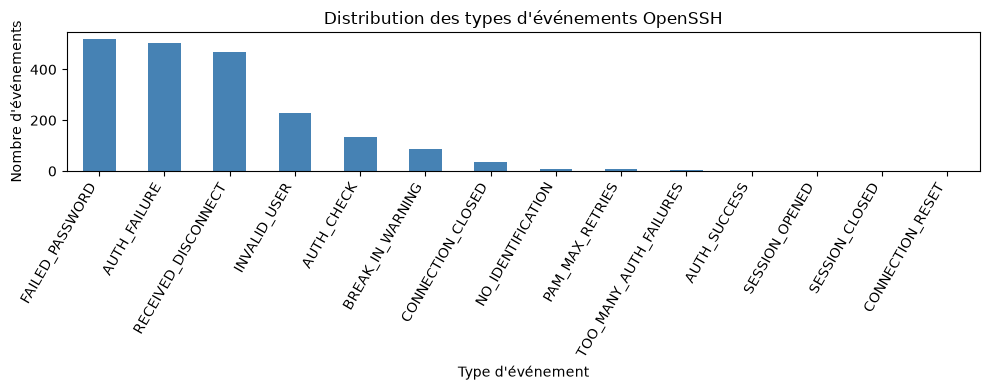

In [5]:
# Distribution des types d'événements
freq = df["type_evenement"].value_counts()
tab = pd.DataFrame({"Nombre": freq, "Pourcentage (%)": (freq / len(df) * 100).round(2)})
display(tab)

freq.plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Distribution des types d'événements OpenSSH")
plt.xlabel("Type d'événement")
plt.ylabel("Nombre d'événements")
plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.show()

**Lecture :** la grande majorité des événements sont des échecs d'authentification
(`FAILED_PASSWORD`, `AUTH_FAILURE`, `INVALID_USER`) et des déconnexions de bots
(`RECEIVED_DISCONNECT`). Les événements de succès ou de session sont extrêmement rares :
ils seront donc de bons candidats « inhabituels ».

## 4. Transformation des événements en vecteurs numériques

### 4.1 Normalisation du message
On remplace les valeurs **variables** par des jetons génériques pour que le modèle compare la
*structure* du message et non ses valeurs :

* adresses IP → `IPADDR`, ports → `PORT`, autres nombres → `NUM`
* **noms d'utilisateur → `USER`** et nom d'hôte DNS → `HOST`

> Remarque importante : sans masquer le nom d'utilisateur, chaque nom rare (`test9`, `chen`…)
> devient un mot rare du TF-IDF et DBSCAN le classe en « bruit » uniquement à cause de ce nom.
> On détecterait alors un artefact du prétraitement et non un comportement anormal.

In [6]:
def normaliser(message):
    m = message.lower()
    m = re.sub(r"\b(?:\d{1,3}\.){3}\d{1,3}\b", "IPADDR", m)                  # adresses IP
    m = re.sub(r"getaddrinfo for \S+", "getaddrinfo for HOST", m)               # nom d'hôte DNS
    m = re.sub(r"invalid user \S+", "invalid user USER", m)                     # utilisateur invalide
    m = re.sub(r"(password for|publickey for|failures for|for user) (?!invalid)\S+",
               r"\1 USER", m)                                                    # autres utilisateurs
    m = re.sub(r"\buser=\S+", "user=USER", m)
    m = re.sub(r"rhost=\S+", "rhost=IPADDR", m)                                  # rhost avec nom DNS éventuel
    m = re.sub(r"\bport\s+\d+", "port PORT", m)                                  # ports
    m = re.sub(r"\b\d+\b", "NUM", m)                                            # nombres restants
    return m

df["message_norm"] = df["message"].apply(normaliser)
for i in [0, 1, 4, 29, 955, 956]:
    print(f"Log {i+1}\n   original : {df.message[i][:110]}\n   normalisé: {df.message_norm[i][:110]}")

print("\nNombre de messages distincts après normalisation :", df["message_norm"].nunique(), "/", len(df))

Log 1
   original : reverse mapping checking getaddrinfo for ns.marryaldkfaczcz.com [173.234.31.186] failed - POSSIBLE BREAK-IN AT
   normalisé: reverse mapping checking getaddrinfo for HOST [IPADDR] failed - possible break-in attempt!
Log 2
   original : Invalid user webmaster from 173.234.31.186
   normalisé: invalid user USER from IPADDR
Log 5
   original : pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=173.234.31.186
   normalisé: pam_unix(sshd:auth): authentication failure; logname= uid=NUM euid=NUM tty=ssh ruser= rhost=IPADDR
Log 30
   original : message repeated 5 times: [ Failed password for root from 5.36.59.76 port 42393 ssh2]
   normalisé: message repeated NUM times: [ failed password for USER from IPADDR port PORT ssh2]
Log 956
   original : Accepted password for fztu from 119.137.62.142 port 49116 ssh2
   normalisé: accepted password for USER from IPADDR port PORT ssh2
Log 957
   original : pam_unix(sshd:session): session opened for

**Observation :** après normalisation, les 2000 logs se réduisent à un petit nombre de
*templates* (modèles de messages). Le clustering va donc retrouver ces gabarits ; les scores
de silhouette seront naturellement élevés et ne doivent pas être sur-interprétés.

### 4.2 Vectorisation TF-IDF

In [7]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),     # mots seuls et paires de mots
    min_df=2,               # on ignore les termes présents dans moins de 2 logs
    max_features=1500,
    sublinear_tf=True,
)
X = vectorizer.fit_transform(df["message_norm"])
X_dense = X.toarray()       # nécessaire pour certaines métriques (Davies-Bouldin, Calinski-Harabasz)
print("Dimensions de la matrice TF-IDF :", X.shape)

Dimensions de la matrice TF-IDF : (2000, 179)


## 5. Modèle 1 – K-Means

### 5.1 Choix du nombre de clusters *k*
Le choix de *k* est justifié par trois critères : la méthode du coude (inertie), le score de
silhouette (à maximiser) et l'indice de Davies-Bouldin (à minimiser).

,k,inertie,silhouette,davies_bouldin
0,2,1099.898,0.411,0.919
1,3,756.047,0.597,1.038
2,4,592.931,0.664,0.941
3,5,423.268,0.753,0.736
4,6,292.158,0.827,0.628
5,7,221.559,0.863,0.707
6,8,179.807,0.883,0.323
7,9,121.324,0.914,0.282
8,10,81.931,0.939,0.243
9,11,64.725,0.953,0.141


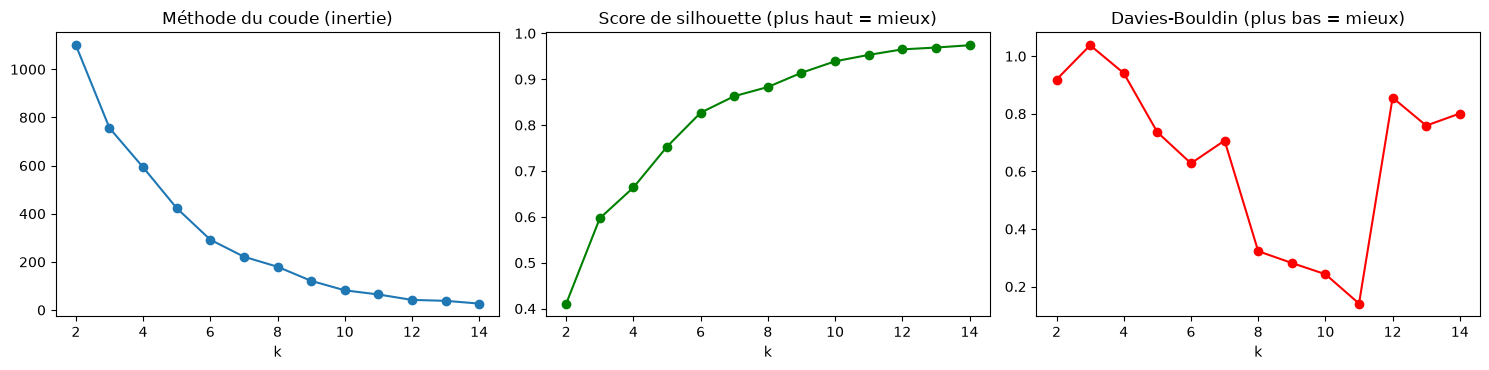

In [8]:
resultats_k = []
for k in range(2, 15):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X)
    resultats_k.append({
        "k": k,
        "inertie": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_, metric="cosine"),
        "davies_bouldin": davies_bouldin_score(X_dense, km.labels_),
    })
df_k = pd.DataFrame(resultats_k).round(3)
display(df_k)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(df_k.k, df_k.inertie, "o-");        ax[0].set_title("Méthode du coude (inertie)")
ax[1].plot(df_k.k, df_k.silhouette, "o-g");    ax[1].set_title("Score de silhouette (plus haut = mieux)")
ax[2].plot(df_k.k, df_k.davies_bouldin, "o-r");ax[2].set_title("Davies-Bouldin (plus bas = mieux)")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

In [9]:
# k retenu : minimum de l'indice de Davies-Bouldin (meilleure séparation des clusters),
# avec un silhouette déjà très élevé et un coude de l'inertie visible dans cette zone.
K_CHOISI = int(df_k.loc[df_k["davies_bouldin"].idxmin(), "k"])
print("k retenu =", K_CHOISI)

k retenu = 11


### 5.2 Entraînement et évaluation de K-Means

In [10]:
kmeans = KMeans(n_clusters=K_CHOISI, random_state=SEED, n_init=20)
df["cluster_kmeans"] = kmeans.fit_predict(X)

sil_km = silhouette_score(X, df["cluster_kmeans"], metric="cosine")
db_km  = davies_bouldin_score(X_dense, df["cluster_kmeans"])
ch_km  = calinski_harabasz_score(X_dense, df["cluster_kmeans"])
print(f"Silhouette : {sil_km:.4f} | Davies-Bouldin : {db_km:.4f} | Calinski-Harabasz : {ch_km:.1f}")

# Contenu de chaque cluster : taille + type d'événement dominant + exemple de message
resume_km = (df.groupby("cluster_kmeans")
               .agg(taille=("ligne", "size"),
                    type_dominant=("type_evenement", lambda s: s.value_counts().index[0]),
                    exemple=("message_norm", "first"))
               .sort_values("taille"))
display(resume_km)

Silhouette : 0.9532 | Davies-Bouldin : 0.1414 | Calinski-Harabasz : 4474.5


,taille,type_dominant,exemple
cluster_kmeans,,,
10,10,NO_IDENTIFICATION,did not receive identification string from IPADDR
4,35,CONNECTION_CLOSED,connection closed by IPADDR [preauth]
8,45,RECEIVED_DISCONNECT,error: received disconnect from IPADDR: NUM: no more user authentication methods available. [preauth]
0,85,BREAK_IN_WARNING,reverse mapping checking getaddrinfo for HOST [IPADDR] failed - possible break-in attempt!
7,113,INVALID_USER,invalid user USER from IPADDR
5,116,INVALID_USER,input_userauth_request: invalid user USER [preauth]
6,135,AUTH_CHECK,pam_unix(sshd:auth): check pass; user unknown
9,139,FAILED_PASSWORD,failed password for invalid user USER from IPADDR port PORT ssh2
1,386,FAILED_PASSWORD,failed password for USER from IPADDR port PORT ssh2


### 5.3 Détection d'anomalies avec K-Means
K-Means ne produit pas directement d'anomalies. On en construit à partir de **deux critères** :

1. **Petits clusters** : un cluster qui contient moins de 1 % des logs représente un comportement rare ;
2. **Distance au centroïde** : un log éloigné du centre de son cluster ressemble peu à ses voisins
   (seuil = 99ᵉ percentile).

In [11]:
# Distance de chaque log au centroïde de son cluster
distances = np.linalg.norm(X_dense - kmeans.cluster_centers_[df["cluster_kmeans"]], axis=1)
df["dist_centroide"] = distances

taille_cluster = df["cluster_kmeans"].map(df["cluster_kmeans"].value_counts())
seuil_dist = np.percentile(distances, 99)

df["anomalie_kmeans"] = (taille_cluster < 0.01 * len(df)) | (distances > seuil_dist)

print("Seuil de distance (99e percentile) :", round(seuil_dist, 3))
print("Anomalies K-Means :", df["anomalie_kmeans"].sum(), f"({df['anomalie_kmeans'].mean()*100:.2f} %)")
display(df[df.anomalie_kmeans].groupby("type_evenement").size().to_frame("Nombre"))

Seuil de distance (99e percentile) : 1.219
Anomalies K-Means : 24 (1.20 %)


,Nombre
type_evenement,
NO_IDENTIFICATION,10
PAM_MAX_RETRIES,7
RECEIVED_DISCONNECT,2
SESSION_CLOSED,1
SESSION_OPENED,1
TOO_MANY_AUTH_FAILURES,3


## 6. Modèle 2 – DBSCAN

DBSCAN regroupe les points denses et marque comme **bruit (-1)** ceux qui n'appartiennent à aucun
groupe : c'est un détecteur d'anomalies naturel.

### 6.1 Choix du paramètre `eps`
On trace la distance au 5ᵉ plus proche voisin (`min_samples = 5`) triée : le « coude » indique un
`eps` pertinent.

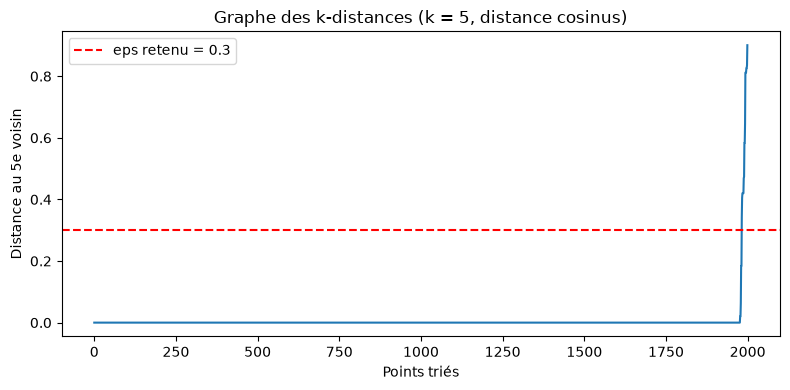

In [12]:
MIN_SAMPLES = 5
voisins = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric="cosine").fit(X)
dist_k = np.sort(voisins.kneighbors(X)[0][:, -1])

plt.figure(figsize=(8, 4))
plt.plot(dist_k)
plt.axhline(0.3, color="r", ls="--", label="eps retenu = 0.3")
plt.title("Graphe des k-distances (k = 5, distance cosinus)")
plt.xlabel("Points triés"); plt.ylabel("Distance au 5e voisin"); plt.legend()
plt.tight_layout(); plt.show()

In [13]:
# Sensibilité au paramètre eps
for eps in [0.1, 0.2, 0.3, 0.45]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES, metric="cosine").fit_predict(X)
    print(f"eps = {eps:<4} -> clusters : {len(set(lab)) - (1 if -1 in lab else 0)} | bruit : {(lab == -1).sum()}")

eps = 0.1  -> clusters : 14 | bruit : 20
eps = 0.2  -> clusters : 13 | bruit : 18
eps = 0.3  -> clusters : 13 | bruit : 18
eps = 0.45 -> clusters : 11 | bruit : 11


In [14]:
EPS = 0.3   # au-dessus de la zone plate du graphe k-distance, résultat stable entre 0.1 et 0.3
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, metric="cosine")
df["cluster_dbscan"] = dbscan.fit_predict(X)
df["anomalie_dbscan"] = df["cluster_dbscan"] == -1

n_clusters_db = len(set(df.cluster_dbscan)) - (1 if -1 in set(df.cluster_dbscan) else 0)
n_bruit = int(df.anomalie_dbscan.sum())
print("Clusters DBSCAN :", n_clusters_db, "| Points de bruit :", n_bruit, f"({n_bruit/len(df)*100:.2f} %)")

# Évaluation : silhouette uniquement sur les points non bruités (le bruit n'a pas de cluster)
masque = ~df["anomalie_dbscan"].values
sil_db = silhouette_score(X[masque], df.loc[masque, "cluster_dbscan"], metric="cosine")
db_db  = davies_bouldin_score(X_dense[masque], df.loc[masque, "cluster_dbscan"])
ch_db  = calinski_harabasz_score(X_dense[masque], df.loc[masque, "cluster_dbscan"])
print(f"Silhouette : {sil_db:.4f} | Davies-Bouldin : {db_db:.4f} | Calinski-Harabasz : {ch_db:.1f}")

print("\nTypes d'événements classés comme bruit :")
display(df[df.anomalie_dbscan].groupby("type_evenement").size().sort_values(ascending=False).to_frame("Nombre"))

Clusters DBSCAN : 13 | Points de bruit : 18 (0.90 %)
Silhouette : 0.9555 | Davies-Bouldin : 0.2157 | Calinski-Harabasz : 4955.2

Types d'événements classés comme bruit :


,Nombre
type_evenement,
INVALID_USER,6
FAILED_PASSWORD,3
RECEIVED_DISCONNECT,3
TOO_MANY_AUTH_FAILURES,3
CONNECTION_RESET,1
SESSION_CLOSED,1
SESSION_OPENED,1


## 7. Évaluation comparative des deux modèles

Il n'existe pas d'étiquette « anomalie » dans le dataset ; l'évaluation est donc :

* **interne** : silhouette, Davies-Bouldin, Calinski-Harabasz ;
* **externe (pseudo-vérité terrain)** : concordance (ARI, NMI) entre les clusters et le type
  d'événement défini par règles. Ce n'est pas une vraie vérité terrain, mais cela mesure si les
  clusters retrouvent des familles d'événements cohérentes.

In [15]:
# ARI / NMI sur les points non bruités pour DBSCAN ; sur tous les points pour K-Means
ari_km = adjusted_rand_score(df.type_evenement, df.cluster_kmeans)
nmi_km = normalized_mutual_info_score(df.type_evenement, df.cluster_kmeans)
ari_db = adjusted_rand_score(df.type_evenement[masque], df.cluster_dbscan[masque])
nmi_db = normalized_mutual_info_score(df.type_evenement[masque], df.cluster_dbscan[masque])

# Accord entre les deux détecteurs d'anomalies
commun = (df.anomalie_kmeans & df.anomalie_dbscan).sum()
union  = (df.anomalie_kmeans | df.anomalie_dbscan).sum()

comparaison = pd.DataFrame({
    "Critère": ["Nombre de clusters", "Anomalies détectées", "% d'anomalies",
                "Silhouette (cosinus)", "Davies-Bouldin (plus bas = mieux)", "Calinski-Harabasz",
                "ARI vs type d'événement", "NMI vs type d'événement",
                "Paramètres"],
    "K-Means": [K_CHOISI, int(df.anomalie_kmeans.sum()), round(df.anomalie_kmeans.mean()*100, 2),
                round(sil_km, 4), round(db_km, 4), round(ch_km, 1), round(ari_km, 3), round(nmi_km, 3),
                f"k={K_CHOISI}"],
    "DBSCAN":  [n_clusters_db, n_bruit, round(df.anomalie_dbscan.mean()*100, 2),
                round(sil_db, 4), round(db_db, 4), round(ch_db, 1), round(ari_db, 3), round(nmi_db, 3),
                f"eps={EPS}, min_samples={MIN_SAMPLES}"],
})
display(comparaison)
print(f"Anomalies communes aux deux modèles : {commun} | union : {union}")

,Critère,K-Means,DBSCAN
0,Nombre de clusters,11,13
1,Anomalies détectées,24,18
2,% d'anomalies,1.2,0.9
3,Silhouette (cosinus),0.9532,0.9555
4,Davies-Bouldin (plus bas = mieux),0.1414,0.2157
5,Calinski-Harabasz,4474.5,4955.2
6,ARI vs type d'événement,0.851,0.936
7,NMI vs type d'événement,0.904,0.945
8,Paramètres,k=11,"eps=0.3, min_samples=5"


Anomalies communes aux deux modèles : 7 | union : 35


## 8. Visualisation des clusters et des anomalies

Les 179 dimensions TF-IDF sont projetées en 2D avec **t-SNE** (distance cosinus). Comme beaucoup
de logs sont identiques après normalisation, ils se superposent : un point visible représente donc
souvent plusieurs logs.

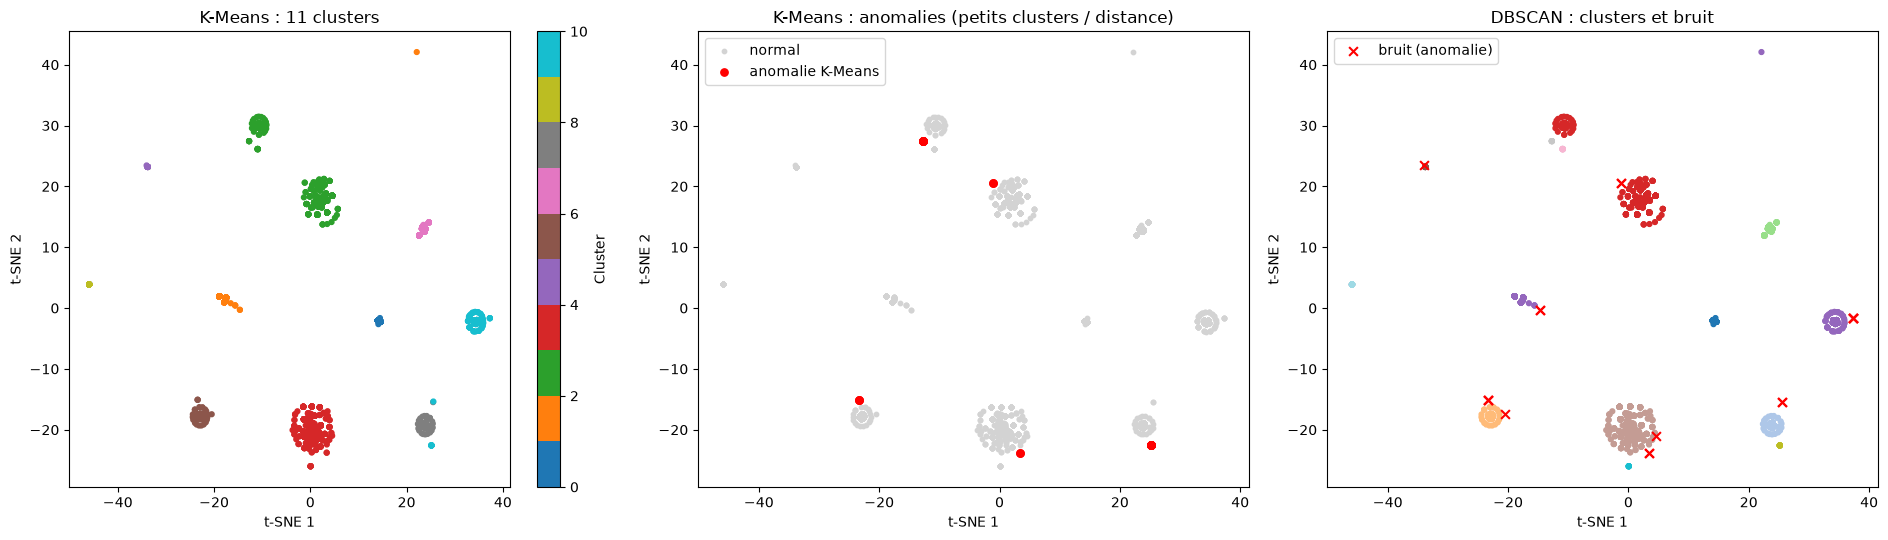

In [16]:
tsne = TSNE(n_components=2, metric="cosine", init="random", perplexity=30, random_state=SEED)
X_2d = tsne.fit_transform(X_dense)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# (a) Clusters K-Means
sc = axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=df.cluster_kmeans, cmap="tab10", s=12)
axes[0].set_title(f"K-Means : {K_CHOISI} clusters"); plt.colorbar(sc, ax=axes[0], label="Cluster")

# (b) Anomalies K-Means
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c="lightgrey", s=10, label="normal")
a = df.anomalie_kmeans.values
axes[1].scatter(X_2d[a, 0], X_2d[a, 1], c="red", s=28, label="anomalie K-Means")
axes[1].set_title("K-Means : anomalies (petits clusters / distance)"); axes[1].legend()

# (c) DBSCAN : clusters en couleur, bruit en rouge
n = ~df.anomalie_dbscan.values
axes[2].scatter(X_2d[n, 0], X_2d[n, 1], c=df.cluster_dbscan[n], cmap="tab20", s=12)
axes[2].scatter(X_2d[~n, 0], X_2d[~n, 1], c="red", marker="x", s=40, label="bruit (anomalie)")
axes[2].set_title("DBSCAN : clusters et bruit"); axes[2].legend()

for ax in axes: ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
plt.tight_layout(); plt.show()

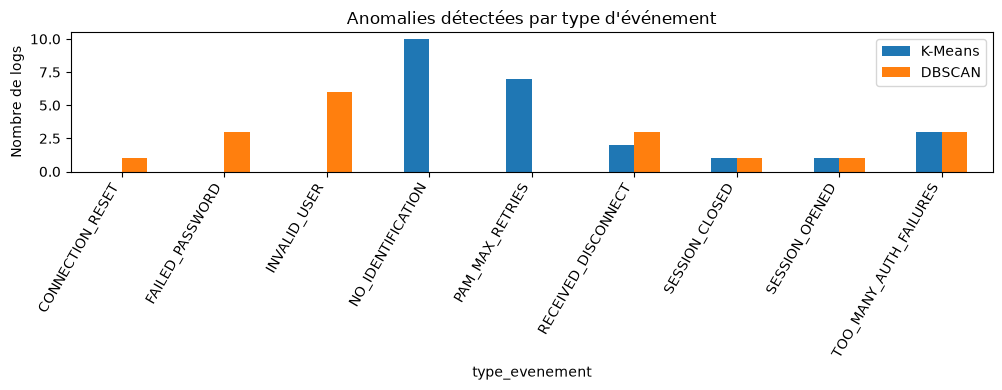

In [17]:
# Comparaison du nombre d'anomalies par type d'événement
comp_types = pd.DataFrame({
    "K-Means": df[df.anomalie_kmeans].type_evenement.value_counts(),
    "DBSCAN":  df[df.anomalie_dbscan].type_evenement.value_counts(),
}).fillna(0).astype(int)
comp_types.plot(kind="bar", figsize=(10, 4))
plt.title("Anomalies détectées par type d'événement")
plt.ylabel("Nombre de logs"); plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.show()

## 9. Interprétation des événements considérés comme suspects

### 9.1 Événements rares signalés par les modèles
On affiche les événements signalés par au moins un modèle, regroupés par type.

In [18]:
df["anomalie_ml"] = df.anomalie_kmeans | df.anomalie_dbscan
rares = (df[df.anomalie_ml]
           .groupby(["type_evenement", "message_norm"]).size()
           .reset_index(name="nombre").sort_values("nombre", ascending=False))
display(rares)

,type_evenement,message_norm,nombre
6,NO_IDENTIFICATION,did not receive identification string from IPADDR,10
7,PAM_MAX_RETRIES,pam service(sshd) ignoring max retries; NUM > NUM,7
3,INVALID_USER,failed none for invalid user USER from IPADDR port PORT ssh2,4
12,TOO_MANY_AUTH_FAILURES,disconnecting: too many authentication failures for USER [preauth],3
2,FAILED_PASSWORD,message repeated NUM times: [ failed password for USER from IPADDR port PORT ssh2],2
8,RECEIVED_DISCONNECT,error: received disconnect from IPADDR: NUM: com.jcraft.jsch.jschexception: auth fail [preauth],2
4,INVALID_USER,input_userauth_request: invalid user NUM [preauth],1
0,CONNECTION_RESET,fatal: write failed: connection reset by peer [preauth],1
1,FAILED_PASSWORD,failed password for invalid user NUM from IPADDR port PORT ssh2,1
5,INVALID_USER,invalid user NUM from IPADDR,1


In [19]:
# Logs originaux des événements les plus significatifs
types_rares = ["AUTH_SUCCESS", "SESSION_OPENED", "SESSION_CLOSED",
               "TOO_MANY_AUTH_FAILURES", "PAM_MAX_RETRIES", "CONNECTION_RESET"]
for _, r in df[df.type_evenement.isin(types_rares)].iterrows():
    print(f"[{r.type_evenement:<22}] ligne {r.ligne:<5} | {r.message[:120]}")

[TOO_MANY_AUTH_FAILURES] ligne 31    | Disconnecting: Too many authentication failures for root [preauth]
[PAM_MAX_RETRIES       ] ligne 33    | PAM service(sshd) ignoring max retries; 6 > 3
[PAM_MAX_RETRIES       ] ligne 223   | PAM service(sshd) ignoring max retries; 5 > 3
[PAM_MAX_RETRIES       ] ligne 239   | PAM service(sshd) ignoring max retries; 5 > 3
[TOO_MANY_AUTH_FAILURES] ligne 286   | Disconnecting: Too many authentication failures for root [preauth]
[PAM_MAX_RETRIES       ] ligne 288   | PAM service(sshd) ignoring max retries; 6 > 3
[PAM_MAX_RETRIES       ] ligne 332   | PAM service(sshd) ignoring max retries; 5 > 3
[PAM_MAX_RETRIES       ] ligne 388   | PAM service(sshd) ignoring max retries; 5 > 3
[AUTH_SUCCESS          ] ligne 956   | Accepted password for fztu from 119.137.62.142 port 49116 ssh2
[SESSION_OPENED        ] ligne 957   | pam_unix(sshd:session): session opened for user fztu by (uid=0)
[SESSION_CLOSED        ] ligne 965   | pam_unix(sshd:session): session cl

### 9.2 Analyse du seul succès d'authentification
La connexion réussie est l'événement le plus important à examiner : un succès **après**
une série d'échecs depuis la même adresse serait le signe d'un brute force abouti.

In [20]:
succes = df[df.type_evenement == "AUTH_SUCCESS"]
for _, s in succes.iterrows():
    print("Succès :", s.message)
    avant = df[(df.ip == s.ip) & (df.ligne < s.ligne)]
    print(f"  -> Activité antérieure de {s.ip} avant ce succès : {len(avant)} événement(s)")
    print(f"  -> Activité totale de cette IP dans le dataset : {(df.ip == s.ip).sum()} événement(s)")
    sess = df[(df.pid == s.pid)]
    print("  -> Événements du même PID :")
    for _, x in sess.iterrows():
        print("     ", x.date.strftime("%H:%M:%S"), x.type_evenement)

Succès : Accepted password for fztu from 119.137.62.142 port 49116 ssh2
  -> Activité antérieure de 119.137.62.142 avant ce succès : 0 événement(s)
  -> Activité totale de cette IP dans le dataset : 2 événement(s)
  -> Événements du même PID :
      09:32:20 AUTH_SUCCESS
      09:32:20 SESSION_OPENED
      09:45:06 SESSION_CLOSED


### 9.3 Adresses IP les plus actives (candidates à un brute force)

In [21]:
echecs = df[df.type_evenement.isin(["FAILED_PASSWORD"])].copy()
echecs["poids"] = echecs["nb_repetitions"]       # une ligne "repeated N times" = N tentatives

profil_ip = (echecs.groupby("ip")
    .agg(tentatives=("poids", "sum"),
         utilisateurs_distincts=("utilisateur", "nunique"),
         premiere=("date", "min"), derniere=("date", "max"))
    .assign(duree_min=lambda d: ((d.derniere - d.premiere).dt.total_seconds() / 60).round(1))
    .sort_values("tentatives", ascending=False))
display(profil_ip.head(10))

# Cibles : comptes les plus attaqués
print("Comptes les plus ciblés (mots de passe échoués) :")
display(echecs.groupby("utilisateur")["poids"].sum().sort_values(ascending=False).head(10).to_frame("tentatives"))

,tentatives,utilisateurs_distincts,premiere,derniere,duree_min
ip,,,,,
183.62.140.253,286,10,2024-12-10 10:54:29,2024-12-10 11:04:43,10.2
187.141.143.180,80,28,2024-12-10 09:12:48,2024-12-10 09:20:02,7.2
103.99.0.122,46,19,2024-12-10 09:11:21,2024-12-10 11:04:45,113.4
112.95.230.3,26,3,2024-12-10 07:27:52,2024-12-10 07:28:51,1.0
5.188.10.180,18,7,2024-12-10 08:24:35,2024-12-10 08:26:24,1.8
185.190.58.151,17,3,2024-12-10 09:07:58,2024-12-10 09:12:59,5.0
123.235.32.19,7,1,2024-12-10 07:32:27,2024-12-10 07:34:23,1.9
106.5.5.195,6,1,2024-12-10 08:39:49,2024-12-10 08:39:59,0.2
119.4.203.64,6,1,2024-12-10 10:14:01,2024-12-10 10:14:13,0.2


Comptes les plus ciblés (mots de passe échoués) :


,tentatives
utilisateur,
root,378
admin,44
oracle,6
support,6
test,5
uucp,5
user,4
guest,3
matlab,3


**Interprétation des types d'événements suspects :**

| Événement | Signification | Niveau de suspicion |
|---|---|---|
| `FAILED_PASSWORD` / `AUTH_FAILURE` en grand nombre depuis une IP | tentative de **brute force** par mot de passe | élevé |
| `INVALID_USER` avec beaucoup de noms différents | **énumération d'utilisateurs** (dictionnaire de logins) | élevé |
| `TOO_MANY_AUTH_FAILURES` / `PAM_MAX_RETRIES` (root, admin) | attaque ciblée sur des comptes privilégiés, seuil de tentatives dépassé | élevé |
| `BREAK_IN_WARNING` | le DNS inverse de l'IP ne correspond pas : message d'**avertissement**, pas une intrusion avérée | moyen |
| `AUTH_SUCCESS` + `SESSION_OPENED/CLOSED` | seule connexion réussie : à **vérifier** (utilisateur légitime ou compte compromis ?) | à valider |
| `CONNECTION_RESET`, `NO_IDENTIFICATION` | connexions anormales / scans de port | faible |

## 10. Méthode de validation des alertes

Les modèles non supervisés produisent des **candidats** ; une alerte n'est confirmée qu'après validation.
La méthode proposée combine une règle explicite, des vérifications automatiques et une revue humaine.

### 10.1 Règle d'alerte explicite (seuil temporel)
Une alerte est déclenchée lorsqu'une même IP cumule **au moins 10 échecs de mot de passe en 5 minutes**.
On compte uniquement `FAILED_PASSWORD` (une ligne = une tentative) afin de ne pas compter trois fois la
même tentative (`Invalid user` + `authentication failure` + `Failed password`).

In [22]:
SEUIL = 10      # nombre minimum de tentatives dans la fenêtre
FENETRE = "5min"

echecs["fenetre"] = echecs["date"].dt.floor(FENETRE)
alertes = (echecs.groupby(["ip", "fenetre"])
             .agg(tentatives=("poids", "sum"),
                  utilisateurs_distincts=("utilisateur", "nunique"))
             .reset_index())
alertes = alertes[alertes.tentatives >= SEUIL].sort_values("tentatives", ascending=False)
print("Nombre d'alertes :", len(alertes), "| IP distinctes :", alertes.ip.nunique())
display(alertes.head(15))

Nombre d'alertes : 10 | IP distinctes : 6


,ip,fenetre,tentatives,utilisateurs_distincts
16,183.62.140.253,2024-12-10 10:55:00,141,8
17,183.62.140.253,2024-12-10 11:00:00,129,1
21,187.141.143.180,2024-12-10 09:15:00,54,27
3,103.99.0.122,2024-12-10 09:10:00,30,19
7,112.95.230.3,2024-12-10 07:25:00,26,3
20,187.141.143.180,2024-12-10 09:10:00,25,1
4,103.99.0.122,2024-12-10 11:00:00,16,12
15,183.62.140.253,2024-12-10 10:50:00,16,3
28,5.188.10.180,2024-12-10 08:25:00,15,4
19,185.190.58.151,2024-12-10 09:10:00,11,2


### 10.2 Vérifications automatiques (corrélation)
Pour chaque IP en alerte on calcule : volume, nombre de comptes testés, durée, cadence (tentatives/minute)
et surtout **si un succès d'authentification existe** pour cette IP (signe de compromission possible).

In [23]:
ips_alerte = alertes.ip.unique()
succes_ips = set(df[df.type_evenement == "AUTH_SUCCESS"].ip)

validation = profil_ip.loc[profil_ip.index.isin(ips_alerte)].copy()
validation["cadence_par_min"] = (validation.tentatives / validation.duree_min.replace(0, np.nan)).round(1)
validation["succes_observe"] = validation.index.isin(succes_ips)
validation["cible_root_admin"] = [
    echecs[(echecs.ip == ip) & echecs.utilisateur.isin(["root", "admin"])].poids.sum() > 0
    for ip in validation.index]

def priorite(r):
    if r.succes_observe:                                    return "CRITIQUE (succès après échecs)"
    if r.tentatives >= 50 or r.utilisateurs_distincts >= 15: return "ÉLEVÉE"   # gros volume ou énumération de comptes
    return "MOYENNE"
validation["priorite"] = validation.apply(priorite, axis=1)
display(validation.sort_values("tentatives", ascending=False))

,tentatives,utilisateurs_distincts,premiere,derniere,duree_min,cadence_par_min,succes_observe,cible_root_admin,priorite
ip,,,,,,,,,
183.62.140.253,286,10,2024-12-10 10:54:29,2024-12-10 11:04:43,10.2,28.0,False,True,ÉLEVÉE
187.141.143.180,80,28,2024-12-10 09:12:48,2024-12-10 09:20:02,7.2,11.1,False,True,ÉLEVÉE
103.99.0.122,46,19,2024-12-10 09:11:21,2024-12-10 11:04:45,113.4,0.4,False,True,ÉLEVÉE
112.95.230.3,26,3,2024-12-10 07:27:52,2024-12-10 07:28:51,1.0,26.0,False,True,MOYENNE
5.188.10.180,18,7,2024-12-10 08:24:35,2024-12-10 08:26:24,1.8,10.0,False,True,MOYENNE
185.190.58.151,17,3,2024-12-10 09:07:58,2024-12-10 09:12:59,5.0,3.4,False,True,MOYENNE


### 10.3 Échantillon à revue humaine
On exporte un échantillon d'alertes pour qu'un analyste attribue une étiquette (vrai positif / faux positif).
Ces étiquettes permettent de calculer la **précision** = VP / (VP + FP) et d'ajuster le seuil.

In [24]:
echantillon = validation.reset_index().head(10)[["ip", "tentatives", "utilisateurs_distincts", "duree_min", "priorite"]]
echantillon["etiquette_analyste"] = ""        # à remplir : VP ou FP
echantillon.to_csv("alertes_a_valider.csv", index=False)
display(echantillon)

def precision(vp, fp):
    """Précision d'un jeu d'alertes après revue humaine."""
    return vp / (vp + fp) if (vp + fp) else float("nan")

,ip,tentatives,utilisateurs_distincts,duree_min,priorite,etiquette_analyste
0,183.62.140.253,286,10,10.2,ÉLEVÉE,
1,187.141.143.180,80,28,7.2,ÉLEVÉE,
2,103.99.0.122,46,19,113.4,ÉLEVÉE,
3,112.95.230.3,26,3,1.0,MOYENNE,
4,5.188.10.180,18,7,1.8,MOYENNE,
5,185.190.58.151,17,3,5.0,MOYENNE,


### 10.4 Procédure complète de validation

1. **Vérification automatique** : volume, cadence, nombre de comptes testés, durée (section 10.2).
2. **Corrélation avec le succès** : un `Accepted password` ou une session ouverte depuis une IP déjà
   en échec est classé **critique** ; ici le succès provient d'une IP sans historique d'échecs.
3. **Réputation externe** : vérification de l'IP dans AbuseIPDB / listes noires (hors ligne, à faire manuellement).
4. **Revue humaine d'un échantillon** pour calculer précision et rappel (section 10.3).
5. **Comparaison avec un outil de référence** (par exemple `fail2ban`, qui bannit après N échecs) afin de vérifier
   que les IP détectées sont bien celles qu'un outil de production bloquerait.
6. **Action** : blocage temporaire de l'IP, désactivation de l'authentification par mot de passe (clé SSH uniquement),
   interdiction de connexion de `root`, puis suivi du taux de faux positifs.

**Limites :** fenêtre fixe de 5 minutes (une fenêtre glissante serait plus robuste), jeu de 2000 logs seulement,
absence de vérité terrain étiquetée, et seuil (10) choisi empiriquement.

## 11. Conclusion générale

### Synthèse des résultats
Nous avons analysé les **2000 logs OpenSSH** du dataset LogHub. Tous les logs respectent le format syslog `sshd` et ont été classés en 14 types d'événements. Après normalisation (IP, ports, nombres, noms d'utilisateur et d'hôte masqués), les 2000 logs se réduisent à seulement **29 gabarits de messages**, vectorisés avec TF-IDF (matrice 2000 × 179).

| Critère | K-Means (k = 11) | DBSCAN (eps = 0,3 ; min_samples = 5) |
|---|---|---|
| Clusters | 11 | 13 |
| Anomalies détectées | 24 (1,2 %) | 18 (0,9 %) |
| Silhouette (cosinus) | 0,953 | 0,956 (hors bruit) |
| Davies-Bouldin (plus bas = mieux) | **0,141** | 0,216 |
| Calinski-Harabasz | 4474 | **4955** |
| ARI / NMI vs type d'événement | 0,851 / 0,904 | **0,936 / 0,945** |

* Les deux modèles retrouvent des familles d'événements cohérentes (scores élevés), avec un léger avantage pour DBSCAN sur la concordance avec les types d'événements.
* **K-Means** impose une affectation de chaque log à un cluster : les anomalies ont été déduites de la taille des clusters et de la distance au centroïde.
* **DBSCAN** détecte directement les anomalies (points de bruit) sans fixer le nombre de clusters, mais dépend de `eps` (résultat stable entre 0,1 et 0,3).
* Les deux modèles ne signalent que **7 anomalies communes** (35 au total) : ils sont complémentaires et ne doivent pas être utilisés isolément.

### Événements suspects identifiés
1. **Brute force SSH** : l'adresse `183.62.140.253` cumule 286 mots de passe échoués en environ 10 minutes (≈ 28 tentatives/min). Les adresses `187.141.143.180` (80 tentatives, 28 comptes différents en 7 min) et `103.99.0.122` (46 tentatives, 19 comptes, attaque lente sur environ 113 min) présentent une **énumération de comptes**.
2. **Cible privilégiée** : les comptes `root` (378 échecs) et `admin` (44 échecs) sont les plus visés ; les messages `Too many authentication failures` et `PAM service(sshd) ignoring max retries` apparaissent comme événements rares dans les deux modèles.
3. **Scans** : 10 messages `Did not receive identification string` forment un petit cluster rare (sondages de port).
4. **Seule connexion réussie** : `fztu` depuis `119.137.62.142` (ligne 956), session ouverte de 09:32:20 à 09:45:06. Cette adresse n'a aucun échec antérieur dans le dataset, donc ce succès n'est **pas** corrélé à une attaque observée ; il reste à vérifier (utilisateur légitime ?).
5. Les avertissements `POSSIBLE BREAK-IN ATTEMPT` correspondent à un échec de résolution DNS inverse et non à une intrusion avérée.

Aucune des adresses en alerte n'a obtenu de connexion réussie : ces comportements sont **compatibles avec des tentatives de brute force et d'énumération**, sans preuve de compromission.

### Validation des alertes
Une règle explicite (au moins 10 échecs de mot de passe en 5 minutes par IP) produit 10 alertes sur 6 adresses IP. Elles sont ensuite priorisées (volume, nombre de comptes testés, succès éventuel), exportées pour une revue humaine (`alertes_a_valider.csv`) et validées par la précision, la réputation externe des IP et la comparaison avec un outil de type `fail2ban`.

### Limites
* Après normalisation il ne reste que 29 gabarits : les scores de silhouette (> 0,95) sont très élevés mais reflètent la simplicité du jeu de données et non une performance exceptionnelle.
* Le type d'événement utilisé comme pseudo-vérité terrain est défini par des mots-clés proches de ceux vus par TF-IDF ; l'ARI et le NMI sont donc indicatifs.
* Il n'y a pas d'étiquette d'anomalie dans le dataset : l'évaluation reste interne et qualitative.
* L'échantillon est petit (2000 logs, environ 4 h 10 de trafic) et la fenêtre de 5 minutes est fixe.
* Une validation humaine et la corrélation avec d'autres sources (pare-feu, réputation d'IP) restent nécessaires avant de confirmer une attaque.